# NB27: Data Assimilation
## Merging Observations with RELIC Simulations

RELIC provides three data assimilation methods:
- **3D-Var**: Variational analysis at a single time
- **4D-Var**: Variational analysis over a time window (adjoint-based)
- **EnKF**: Ensemble Kalman Filter (sequential, flow-dependent covariance)

**Key module**: `relic.optimization.assimilation`

$$\mathbf{x}^a = \mathbf{x}^b + \mathbf{K}(\mathbf{y} - \mathbf{H}\mathbf{x}^b)$$

where $\mathbf{K} = \mathbf{B}\mathbf{H}^T(\mathbf{H}\mathbf{B}\mathbf{H}^T + \mathbf{R})^{-1}$

---

## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


## Learning Goals

- Run a RELIC twin experiment that compares open-loop, EnKF, and 3D-Var analyses.
- Inspect innovations, analysis increments, spread, and cost diagnostics from the real assimilation modules.
- Evaluate whether the assimilation plots communicate skill improvement clearly enough for tutorial release.


In [1]:
# --- Environment Guard (prevent OpenMP duplicate lib crash) ---
import os
import sys
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', message='The pynvml package is deprecated.*')
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'


DEFAULT_PROJECT_ROOT = Path(os.environ.get('RELIC_PROJECT_ROOT', os.getcwd()))


def locate_project_root() -> Path:
    candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents, DEFAULT_PROJECT_ROOT]
    for candidate in candidates:
        if (candidate / 'relic').is_dir() and (candidate / 'docs' / 'source' / 'architecture_overview.md').is_file():
            return candidate.resolve()
    raise FileNotFoundError('Could not locate RELIC project root. Set RELIC_PROJECT_ROOT if needed.')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch

from relic.optimization.assimilation.base import (
    Assimilator, AssimilationMethod, AssimilationConfig,
    Observation, ObservationSet, IdentityOperator,
)
from relic.optimization.assimilation.enkf import (
    EnsembleKalmanFilter, EnKFConfig,
)
from relic.optimization.assimilation.variational import (
    ThreeDVar, FourDVar, VariationalConfig,
)

print('[OK] Data Assimilation modules loaded')
print(f'  Methods: {[m.value for m in AssimilationMethod]}')
print(f'  EnKF: {EnsembleKalmanFilter.__module__}')
print(f'  3DVar: {ThreeDVar.__module__}')
print(f'  4DVar: {FourDVar.__module__}')

[OK] Data Assimilation modules loaded
  Methods: ['enkf', 'ekf', '3dvar', '4dvar', 'pf']
  EnKF: relic.optimization.assimilation.enkf
  3DVar: relic.optimization.assimilation.variational
  4DVar: relic.optimization.assimilation.variational


## 1. Observation Specification

Define observations with uncertainty (error covariance) using
RELIC's `Observation` and `ObservationSet` classes. `quality_flag` is
required. The units below are explanatory observation metadata; the observation
container does not perform a unit conversion or establish unit consistency.


In [2]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980) -- biochemical photosynthesis model.
#   Evensen (2003) -- twin-experiment assimilation benchmarking.
# Mathematical expression:
#   y_k = H(x_true,k) + epsilon_k
#   epsilon_k ~ N(0, sigma_obs^2)
# Parameter meanings:
#   truth_photosynthesis: gross-photosynthesis trajectory from a production RELIC functor.
#   obs_sigma: observation standard deviation [umol CO2 m-2 s-1].
#   error_variance: sigma_obs^2 used by assimilation methods.
# Units:
#   Gross photosynthesis and observation error use umol CO2 m-2 s-1.
# Domain/constraints:
#   Canonical Farquhar forcings are finite; observations are non-negative and time aligned.
# Sign convention:
#   Positive gross photosynthesis denotes atmospheric CO2 uptake.
# ---------------------------------------------------------------

import math
import torch

from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
from relic.utils.time_constants import SECONDS_PER_DAY


torch.manual_seed(27)

n_cycles = 14
ASSIMILATED_VARIABLE = 'gross_photosynthesis'
forecast_times = torch.arange(0.0, float(n_cycles), 1.0, dtype=torch.float32)
truth_model = FarquharPhotosynthesis(
    name='tutorial_assimilation_truth',
    enable_gpu=False,
)


def unwrap_update(value):
    return value.value if hasattr(value, 'value') else value

forcing_series = {
    'air_temperature': [],
    'ppfd': [],
    'vapor_pressure_deficit': [],
    'leaf_area_index': [],
    'water_stress_factor': [],
}
truth_photosynthesis_values = []

for cycle_index in range(n_cycles):
    phase = 2.0 * math.pi * cycle_index / n_cycles
    temperature_k = 297.2 + 2.6 * math.sin(phase) + 0.8 * math.cos(2.0 * phase)
    par = max(280.0, 920.0 + 260.0 * math.sin(phase + 0.35))
    vpd = max(0.35, 0.75 + 0.22 * math.cos(phase - 0.20))
    lai = 3.3 + 0.35 * math.sin(phase + 0.60)
    water_stress = min(1.0, max(0.58, 0.80 + 0.14 * math.cos(phase - 0.70)))

    forcing_series['air_temperature'].append(temperature_k)
    forcing_series['ppfd'].append(par)
    forcing_series['vapor_pressure_deficit'].append(vpd * 1000.0)
    forcing_series['leaf_area_index'].append(lai)
    forcing_series['water_stress_factor'].append(water_stress)

    truth_output = truth_model(
        {
            'air_temperature': torch.tensor(temperature_k, dtype=torch.float32),
            'atmospheric_co2_ppm': torch.tensor(412.0, dtype=torch.float32),
            'ppfd': torch.tensor(par, dtype=torch.float32),
            'vcmax_scaling': torch.tensor(0.95, dtype=torch.float32),
            'jmax_scaling': torch.tensor(0.95, dtype=torch.float32),
            'water_stress_factor': torch.tensor(water_stress, dtype=torch.float32),
            'temperature_stress_factor': torch.tensor(1.0, dtype=torch.float32),
            'ozone_stress_factor': torch.tensor(1.0, dtype=torch.float32),
            'vapor_pressure_deficit': torch.tensor(vpd * 1000.0, dtype=torch.float32),
            'leaf_area_index': torch.tensor(lai, dtype=torch.float32),
            'leaf_water_potential': torch.tensor(-0.7, dtype=torch.float32),
        },
        time=float(cycle_index) * float(SECONDS_PER_DAY),
        dt=float(SECONDS_PER_DAY),
    )
    truth_photosynthesis_values.append(
        float(unwrap_update(truth_output['gross_photosynthesis']).detach().cpu().item())
    )

for key, values in forcing_series.items():
    forcing_series[key] = torch.tensor(values, dtype=torch.float32)
truth_photosynthesis_series = torch.tensor(truth_photosynthesis_values, dtype=torch.float32)
obs_sigma = 1.20
obs_noise = torch.randn(n_cycles, dtype=torch.float32) * obs_sigma
obs_values_tensor = torch.clamp(truth_photosynthesis_series + obs_noise, min=0.0)
obs_error_variance = torch.tensor([obs_sigma ** 2], dtype=torch.float32)

observations = []
for cycle_index, cycle_time in enumerate(forecast_times):
    observations.append(
        Observation(
            value=obs_values_tensor[cycle_index:cycle_index + 1],
            error_variance=obs_error_variance,
            coordinates=(0.0, 0.0, 0.0),
            time=float(cycle_time.item()),
            variable_name=ASSIMILATED_VARIABLE,
            quality_flag=0,
            metadata={'units': 'umol CO2 m-2 s-1'},
        )
    )

obs_set = ObservationSet(observations=observations, time=0.0)
print('=== Observation Set from RELIC Twin Experiment ===')
print('  Variable: gross_photosynthesis')
print(f'  N observations: {len(observations)}')
print(f'  Truth range: [{float(truth_photosynthesis_series.min()):.2f}, {float(truth_photosynthesis_series.max()):.2f}]')
print(f'  Observation range: [{float(obs_values_tensor.min()):.2f}, {float(obs_values_tensor.max()):.2f}]')
print(f'  Observation sigma: {obs_sigma:.2f}')
print('[OK] Observation set created from actual RELIC truth trajectory')

=== Observation Set from RELIC Twin Experiment ===
  Variable: gross_photosynthesis
  N observations: 14
  Truth range: [12.72, 21.27]
  Observation range: [13.12, 22.65]
  Observation sigma: 1.20
[OK] Observation set created from actual RELIC truth trajectory


## 2. Observation Operator

The observation operator $\mathbf{H}$ maps model state to observation space.
`IdentityOperator` is used when observations directly correspond to state variables.


In [3]:
# References: RELIC IdentityOperator and Evensen (2003).
# Mathematical expression: y = H(x) = x for the observed component.
# Parameter meanings: variable_names selects the directly observed state component.
# Units: input and output both use umol CO2 m-2 s-1.
# Domain/constraints: the named component must exist in both state and observation payloads.
# Sign convention: positive values denote atmospheric CO2 uptake.
H = IdentityOperator(variable_names=[ASSIMILATED_VARIABLE])
print("=== Observation Operator ===")
print(f"  Type: {type(H).__name__}")
print(f"  Variables: {H.variable_names}")
print("[OK] Observation operator created")


=== Observation Operator ===
  Type: IdentityOperator
  Variables: ['gross_photosynthesis']
[OK] Observation operator created


## 3. Ensemble Kalman Filter (EnKF)

The EnKF uses an ensemble of model states to estimate
the background error covariance $\mathbf{B}$ flow-dependently.

$$\mathbf{x}_i^a = \mathbf{x}_i^b + \mathbf{K}(\mathbf{y} + \epsilon_i - \mathbf{H}\mathbf{x}_i^b)$$

Reference: Evensen (2003), Ocean Dynamics 53:343-367


In [4]:
# ---------------------------------------------------------------
# References:
#   Farquhar et al. (1980) -- production functor used to generate the prior.
#   Evensen (2003); Burgers et al. (1998) -- Ensemble Kalman Filter.
#   Talagrand and Courtier (1987) -- 3D-Var formulation.
# Mathematical expression:
#   x_f(k) = x_a(k-1) + (x_open_loop(k) - x_open_loop(k-1))
#   x_a = x_f + K * (y - H(x_f))
#   J(x) = 0.5 * (x - x_b)^T B^{-1} (x - x_b)
#        + 0.5 * (H(x) - y)^T R^{-1} (H(x) - y)
# Parameter meanings:
#   open_loop_photosynthesis: prior gross-photosynthesis trajectory from a mismatched production functor.
#   covariance_inflation: multiplicative spread inflation in EnKF.
#   obs_error_variance: twin-experiment observation error variance.
#   background_error_scale: 3D-Var background penalty scale.
# Units:
#   State, observation, innovation, and RMSE use umol CO2 m-2 s-1.
# Domain/constraints:
#   State and observation names, shapes, units, and cycle times must agree exactly.
# Sign convention:
#   Innovation is observation minus forecast; positive analysis increments increase uptake.
# ---------------------------------------------------------------
import torch

from relic.core.simulator import RELICSimulator
from relic.core.state import StateManager
from relic.parameters import get_global_manager
from relic.scientific.biosphere.photosynthesis.farquhar import FarquharPhotosynthesis
prior_model = FarquharPhotosynthesis(
    name='tutorial_assimilation_prior',
    enable_gpu=False,
)

open_loop_photosynthesis = []
for cycle_index in range(n_cycles):
    prior_output = prior_model(
        {
            'air_temperature': forcing_series['air_temperature'][cycle_index:cycle_index + 1].reshape(()),
            'atmospheric_co2_ppm': torch.tensor(412.0, dtype=torch.float32),
            'ppfd': forcing_series['ppfd'][cycle_index:cycle_index + 1].reshape(()),
            'vcmax_scaling': torch.tensor(0.82, dtype=torch.float32),
            'jmax_scaling': torch.tensor(0.82, dtype=torch.float32),
            'water_stress_factor': forcing_series['water_stress_factor'][cycle_index:cycle_index + 1].reshape(()),
            'temperature_stress_factor': torch.tensor(1.0, dtype=torch.float32),
            'ozone_stress_factor': torch.tensor(1.0, dtype=torch.float32),
            'vapor_pressure_deficit': forcing_series['vapor_pressure_deficit'][cycle_index:cycle_index + 1].reshape(()),
            'leaf_area_index': forcing_series['leaf_area_index'][cycle_index:cycle_index + 1].reshape(()),
            'leaf_water_potential': torch.tensor(-0.9, dtype=torch.float32),
        },
        time=float(cycle_index) * float(SECONDS_PER_DAY),
        dt=float(SECONDS_PER_DAY),
    )
    open_loop_photosynthesis.append(
        unwrap_update(prior_output['gross_photosynthesis']).detach().to(dtype=torch.float32).reshape(1)
    )

open_loop_photosynthesis = torch.cat(open_loop_photosynthesis)

state_manager = StateManager()
simulator = RELICSimulator()
simulator.set_state_manager(state_manager)
parameter_manager = get_global_manager()

enkf_config = EnKFConfig(
    ensemble_size=32,
    initial_perturbation_std=2.50,
    covariance_inflation=1.12,
    regularization=1.0e-6,
    efficient_gain=True,
)
var_config = VariationalConfig(
    method=AssimilationMethod.VARIATIONAL_3D,
    max_iterations=30,
    convergence_tolerance=1.0e-6,
    background_error_scale=1.0,
)

enkf = EnsembleKalmanFilter(simulator, state_manager, parameter_manager, enkf_config)
threedvar = ThreeDVar(simulator, state_manager, parameter_manager, var_config)

enkf_state = {ASSIMILATED_VARIABLE: open_loop_photosynthesis[0:1].detach().clone()}
enkf.initialize_ensemble(enkf_state)
var_state = {ASSIMILATED_VARIABLE: open_loop_photosynthesis[0:1].detach().clone()}

open_loop_photosynthesis_series = []
truth_photosynthesis_plot_series = truth_photosynthesis_series.detach().cpu().tolist()
enkf_forecast_series = []
enkf_analysis_series = []
enkf_innovation_series = []
enkf_spread_series = []
enkf_observation_series = []
var_forecast_series = []
var_analysis_series = []
var_innovation_series = []
var_final_cost_series = []
var_iteration_series = []

for cycle_index, obs in enumerate(observations):
    prior_from_model = {ASSIMILATED_VARIABLE: open_loop_photosynthesis[cycle_index:cycle_index + 1].detach().clone()}
    if cycle_index > 0:
        model_increment = (open_loop_photosynthesis[cycle_index] - open_loop_photosynthesis[cycle_index - 1]).reshape(1)
        enkf_state = {ASSIMILATED_VARIABLE: (enkf_state[ASSIMILATED_VARIABLE] + model_increment).detach().clone()}
        enkf.ensemble_states[ASSIMILATED_VARIABLE] = (
            enkf.ensemble_states[ASSIMILATED_VARIABLE] + model_increment
        ).detach().clone()
        var_state = {ASSIMILATED_VARIABLE: (var_state[ASSIMILATED_VARIABLE] + model_increment).detach().clone()}

    obs_cycle = ObservationSet(observations=[obs], time=obs.time)

    enkf_result = enkf.assimilate(enkf_state, obs_cycle, H)
    enkf_stats = enkf.get_ensemble_statistics()
    background_covariance = torch.eye(var_state[ASSIMILATED_VARIABLE].numel(), dtype=torch.float32)
    var_result = threedvar.assimilate(var_state, obs_cycle, H, background_covariance)

    open_loop_photosynthesis_series.append(float(prior_from_model[ASSIMILATED_VARIABLE].detach().cpu().item()))
    enkf_forecast_series.append(float(enkf_result.forecast_mean[ASSIMILATED_VARIABLE].detach().cpu().item()))
    enkf_analysis_series.append(float(enkf_result.analysis_mean[ASSIMILATED_VARIABLE].detach().cpu().item()))
    enkf_innovation_series.append(float(enkf_result.innovation.detach().cpu().reshape(-1)[0].item()))
    enkf_spread_series.append(float(enkf_stats[ASSIMILATED_VARIABLE]['ensemble_spread']))
    enkf_observation_series.append(float(obs.value.detach().cpu().reshape(-1)[0].item()))

    var_forecast_series.append(float(var_result.forecast_mean[ASSIMILATED_VARIABLE].detach().cpu().item()))
    var_analysis_series.append(float(var_result.analysis_mean[ASSIMILATED_VARIABLE].detach().cpu().item()))
    var_innovation_series.append(float(var_result.innovation.detach().cpu().reshape(-1)[0].item()))
    var_final_cost_series.append(float(var_result.metadata['final_cost']))
    var_iteration_series.append(int(var_result.metadata['iterations']))

    enkf_state = {name: value.detach().clone() for name, value in enkf_result.analysis_mean.items()}
    var_state = {name: value.detach().clone() for name, value in var_result.analysis_mean.items()}

open_loop_rmse = float(torch.sqrt(torch.mean((torch.tensor(open_loop_photosynthesis_series) - truth_photosynthesis_series) ** 2)).item())
enkf_rmse = float(torch.sqrt(torch.mean((torch.tensor(enkf_analysis_series) - truth_photosynthesis_series) ** 2)).item())
var_rmse = float(torch.sqrt(torch.mean((torch.tensor(var_analysis_series) - truth_photosynthesis_series) ** 2)).item())

print('=== RELIC Twin-Experiment Assimilation Cycles Completed ===')
print(f'  Truth range:          [{min(truth_photosynthesis_plot_series):.2f}, {max(truth_photosynthesis_plot_series):.2f}]')
print(f'  Open-loop range:      [{min(open_loop_photosynthesis_series):.2f}, {max(open_loop_photosynthesis_series):.2f}]')
print(f'  Observation range:    [{min(enkf_observation_series):.2f}, {max(enkf_observation_series):.2f}]')
print(f'  Mean EnKF spread:     {sum(enkf_spread_series) / len(enkf_spread_series):.3f}')
print(f'  Mean |EnKF innov.|:   {sum(abs(v) for v in enkf_innovation_series) / len(enkf_innovation_series):.3f}')
print(f'  Mean |3DVar innov.|:  {sum(abs(v) for v in var_innovation_series) / len(var_innovation_series):.3f}')
print(f'  Open-loop RMSE:       {open_loop_rmse:.3f}')
print(f'  EnKF analysis RMSE:   {enkf_rmse:.3f}')
print(f'  3DVar analysis RMSE:  {var_rmse:.3f}')
print(f'  Mean 3DVar cost:      {sum(var_final_cost_series) / len(var_final_cost_series):.3f}')
if enkf_rmse >= open_loop_rmse:
    raise ValueError('EnKF analysis did not improve over the open-loop prior.')
if var_rmse >= open_loop_rmse:
    raise ValueError('3D-Var analysis did not improve over the open-loop prior.')
print('[OK] Open-loop forecast, EnKF, and 3D-Var runs are ready for diagnostics')

=== RELIC Twin-Experiment Assimilation Cycles Completed ===
  Truth range:          [12.72, 21.27]
  Open-loop range:      [11.55, 18.95]
  Observation range:    [13.12, 22.65]
  Mean EnKF spread:     0.761
  Mean |EnKF innov.|:   1.091
  Mean |3DVar innov.|:  1.075
  Open-loop RMSE:       1.794
  EnKF analysis RMSE:   0.900
  3DVar analysis RMSE:  0.870
  Mean 3DVar cost:      0.682
[OK] Open-loop forecast, EnKF, and 3D-Var runs are ready for diagnostics


## 4. 3D-Var

Variational data assimilation minimizes a cost function:

$$
J(\mathbf{x}) = \frac{1}{2}(\mathbf{x}-\mathbf{x}^b)^T \mathbf{B}^{-1} (\mathbf{x}-\mathbf{x}^b)
+ \frac{1}{2}(\mathbf{y}-\mathbf{H}\mathbf{x})^T \mathbf{R}^{-1} (\mathbf{y}-\mathbf{H}\mathbf{x})
$$

Reference: Courtier et al. (1998), QJRMS


=== Data Assimilation Visualization ===


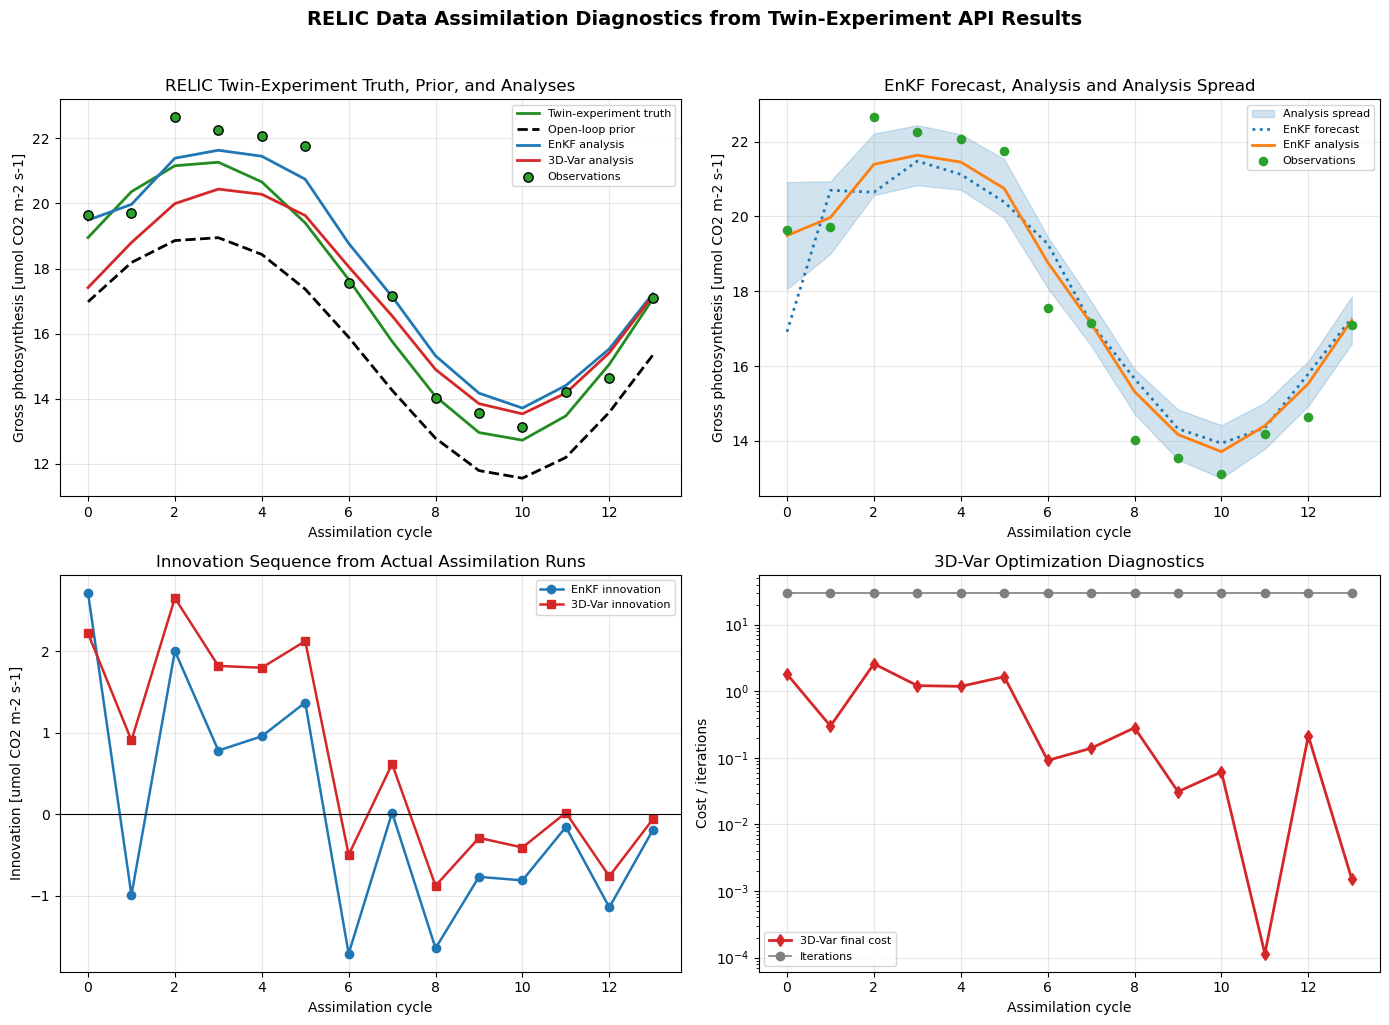

[OK] Data assimilation visualization generated from actual RELIC twin-experiment outputs


In [5]:
# ---------------------------------------------------------------
# References:
#   Taylor (2001) -- forecast-vs-analysis diagnostic plotting.
#   Evensen (2003) -- ensemble spread and innovation diagnostics.
# Mathematical expression:
#   innovation_k = y_k - H(x_f,k)
#   spread_k = std(ensemble_k)
# Parameter meanings:
#   truth_photosynthesis_plot_series: RELIC truth trajectory used for observation generation.
#   open_loop_photosynthesis_series: mismatched RELIC prior trajectory.
#   enkf_spread_series: ensemble standard deviation after the analysis update.
#   var_final_cost_series: final minimized 3D-Var cost per cycle.
# Units:
#   State, observation, innovation, and spread use umol CO2 m-2 s-1.
# Domain/constraints:
#   All plotted sequences share the same ordered assimilation-cycle axis.
# Sign convention:
#   Positive innovation means the observation exceeds the forecast.
# ---------------------------------------------------------------
import matplotlib.pyplot as plt
from IPython.display import display

print('=== Data Assimilation Visualization ===')

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
time_axis = forecast_times.detach().cpu().tolist()

# Panel 1: truth, prior, and analyses
ax = axes[0, 0]
ax.plot(time_axis, truth_photosynthesis_plot_series, linewidth=2.0, color='forestgreen', label='Twin-experiment truth')
ax.plot(time_axis, open_loop_photosynthesis_series, linestyle='--', linewidth=2.0, color='black', label='Open-loop prior')
ax.plot(time_axis, enkf_analysis_series, linewidth=2.0, color='tab:blue', label='EnKF analysis')
ax.plot(time_axis, var_analysis_series, linewidth=2.0, color='tab:red', label='3D-Var analysis')
ax.scatter(time_axis, enkf_observation_series, color='tab:green', edgecolors='black', s=45, zorder=5, label='Observations')
ax.set_xlabel('Assimilation cycle')
ax.set_ylabel('Gross photosynthesis [umol CO2 m-2 s-1]')
ax.set_title('RELIC Twin-Experiment Truth, Prior, and Analyses')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Panel 2: EnKF forecast and spread diagnostics
ax = axes[0, 1]
spread_lower = [mean - spread for mean, spread in zip(enkf_analysis_series, enkf_spread_series)]
spread_upper = [mean + spread for mean, spread in zip(enkf_analysis_series, enkf_spread_series)]
ax.fill_between(time_axis, spread_lower, spread_upper, color='tab:blue', alpha=0.20, label='Analysis spread')
ax.plot(time_axis, enkf_forecast_series, linestyle=':', linewidth=2.0, color='tab:blue', label='EnKF forecast')
ax.plot(time_axis, enkf_analysis_series, linewidth=2.0, color='tab:orange', label='EnKF analysis')
ax.scatter(time_axis, enkf_observation_series, color='tab:green', s=35, zorder=5, label='Observations')
ax.set_xlabel('Assimilation cycle')
ax.set_ylabel('Gross photosynthesis [umol CO2 m-2 s-1]')
ax.set_title('EnKF Forecast, Analysis and Analysis Spread')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Panel 3: innovation diagnostics for both methods
ax = axes[1, 0]
ax.plot(time_axis, enkf_innovation_series, marker='o', linewidth=1.8, color='tab:blue', label='EnKF innovation')
ax.plot(time_axis, var_innovation_series, marker='s', linewidth=1.8, color='tab:red', label='3D-Var innovation')
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set_xlabel('Assimilation cycle')
ax.set_ylabel('Innovation [umol CO2 m-2 s-1]')
ax.set_title('Innovation Sequence from Actual Assimilation Runs')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Panel 4: 3D-Var cost convergence per cycle
ax = axes[1, 1]
ax.semilogy(time_axis, var_final_cost_series, marker='d', linewidth=2.0, color='tab:red', label='3D-Var final cost')
ax.plot(time_axis, var_iteration_series, marker='o', linewidth=1.2, color='tab:gray', label='Iterations')
ax.set_xlabel('Assimilation cycle')
ax.set_ylabel('Cost / iterations')
ax.set_title('3D-Var Optimization Diagnostics')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.suptitle('RELIC Data Assimilation Diagnostics from Twin-Experiment API Results', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
display(plt.gcf())
plt.close(plt.gcf())
print('[OK] Data assimilation visualization generated from actual RELIC twin-experiment outputs')

In [6]:
# ---------------------------------------------------------------
# References:
#   Talagrand and Courtier (1987) -- variational analysis.
# Mathematical expression:
#   J(x_a) < J(x_b) indicates that the optimized analysis reduces the
#   combined background-and-observation mismatch relative to the prior.
# Parameter meanings:
#   var_iteration_series: optimizer iterations per cycle.
#   var_final_cost_series: terminal cost after 3D-Var minimization.
# Units:
#   Forecast and analysis use umol CO2 m-2 s-1; the normalized cost is dimensionless.
# Domain/constraints:
#   Each cycle reports finite optimizer cost and a positive bounded iteration count.
# Sign convention:
#   Lower final cost denotes a closer joint fit to background and observation.
# ---------------------------------------------------------------
print("=== 3D-Var Configuration ===")
print(f"  Method: {var_config.method.value}")
print(f"  Max iterations: {var_config.max_iterations}")
print(f"  Convergence tolerance: {var_config.convergence_tolerance}")
print(f"  Background error scale: {var_config.background_error_scale}")
print()
print("=== Actual 3D-Var Diagnostics ===")
print(f"  Mean forecast gross photosynthesis: {sum(var_forecast_series) / len(var_forecast_series):.3f}")
print(f"  Mean analysis gross photosynthesis: {sum(var_analysis_series) / len(var_analysis_series):.3f}")
print(f"  Mean absolute innovation: {sum(abs(v) for v in var_innovation_series) / len(var_innovation_series):.3f}")
print(f"  Mean final cost: {sum(var_final_cost_series) / len(var_final_cost_series):.3f}")
print(f"  Mean iterations: {sum(var_iteration_series) / len(var_iteration_series):.1f}")
print()
print("Cycle | Forecast | Analysis | Observation | Innovation | FinalCost | Iter")
for idx, (forecast_value, analysis_value, observation_value, innovation_value, final_cost, iterations) in enumerate(
    zip(
        var_forecast_series,
        var_analysis_series,
        enkf_observation_series,
        var_innovation_series,
        var_final_cost_series,
        var_iteration_series,
    )
):
    print(
        f"  {idx:02d}  | {forecast_value:8.3f} | {analysis_value:8.3f} | {observation_value:11.3f} |"
        f" {innovation_value:10.3f} | {final_cost:9.4f} | {iterations:4d}"
    )

print("[OK] 3D-Var summary reported from actual RELIC optimization results")

=== 3D-Var Configuration ===
  Method: 3dvar
  Max iterations: 30
  Convergence tolerance: 1e-06
  Background error scale: 1.0

=== Actual 3D-Var Diagnostics ===
  Mean forecast gross photosynthesis: 17.025
  Mean analysis gross photosynthesis: 17.155
  Mean absolute innovation: 1.075
  Mean final cost: 0.682
  Mean iterations: 30.0

Cycle | Forecast | Analysis | Observation | Innovation | FinalCost | Iter
  00  |   16.975 |   17.412 |      19.631 |      2.219 |    1.8054 |   30
  01  |   18.622 |   18.800 |      19.705 |      0.905 |    0.3002 |   30
  02  |   19.475 |   19.997 |      22.649 |      2.652 |    2.5783 |   30
  03  |   20.085 |   20.442 |      22.262 |      1.819 |    1.2131 |   30
  04  |   19.929 |   20.283 |      22.079 |      1.797 |    1.1837 |   30
  05  |   19.214 |   19.632 |      21.756 |      2.124 |    1.6534 |   30
  06  |   18.153 |   18.055 |      17.556 |     -0.499 |    0.0914 |   30
  07  |   16.423 |   16.544 |      17.161 |      0.616 |    0.1393 |   3

## Summary

| Method | Class | Update Type | Covariance |
|---|---|---|---|
| EnKF | `EnsembleKalmanFilter` | Sequential | Flow-dependent (ensemble) |
| 3D-Var | `ThreeDVar` | Variational | Static B matrix |
| 4D-Var | `FourDVar` | Variational (time window) | Adjoint-based |

**Scope**: This notebook executes EnKF and 3D-Var analysis APIs only. Forecast
increments are explicitly prescribed from the open-loop Farquhar trajectory;
there is no hidden EnKF model-forward implementation or StateManager feedback
commit. 4D-Var requires its own differentiable forward-model binding and time
window; `torch.nn.Module` membership alone does not establish an adjoint for
events, clipping or adaptive decisions.
